# Lecture 5.1 · Multiple Regression II

Following `05_1_Multiple linear regression II.pdf` (Kutner et al., 2005, Ch. 7): extra sums of squares, partial $F$ tests,
partial determination, standardized regression, multicollinearity.

**Data:** `tips.csv`, $n=244$. $Y$ = `tip`; $X_1$ = `total_bill`, $X_2$ = `size`, and
$X_3$ = `per_person` $=X_1/X_2$ (bill per diner). $X_3$ is **derived** from $X_1$ and $X_2$, so the overlap between
predictors below is partly built in, which is what makes it a usable multicollinearity example.

In [1]:
import numpy as np, pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

ALPHA = 0.05
df = pd.read_csv('tips.csv')
df['per_person'] = df['total_bill'] / df['size']
Y = df['tip'].to_numpy()
n = len(Y)
V = {'X1': df['total_bill'].to_numpy(), 'X2': df['size'].to_numpy().astype(float), 'X3': df['per_person'].to_numpy()}
name = {'X1': 'total_bill', 'X2': 'size', 'X3': 'per_person'}
SSTO = ((Y - Y.mean())**2).sum()

def fit(keys):
    Xm = np.column_stack([np.ones(n)] + [V[k] for k in keys])
    b = np.linalg.lstsq(Xm, Y, rcond=None)[0]
    e = Y - Xm @ b
    p = Xm.shape[1]
    sse = e @ e
    return dict(keys=keys, X=Xm, b=b, e=e, p=p, SSE=sse, MSE=sse / (n - p), R2=1 - sse / SSTO,
                cov=sse / (n - p) * np.linalg.inv(Xm.T @ Xm))

models = {k: fit(k) for k in [(), ('X1',), ('X2',), ('X3',), ('X1', 'X2'), ('X1', 'X3'), ('X2', 'X3'), ('X1', 'X2', 'X3')]}
models[()]['SSE'] = SSTO
F3 = models[('X1', 'X2', 'X3')]

print(df[['tip', 'total_bill', 'size', 'per_person']].describe().round(3))
print(f'\n{"model":<22}{"p":>3}{"SSE":>10}{"SSR":>10}{"R2":>8}')
for k, m in models.items():
    print(f'{"+".join(k) or "(intercept only)":<22}{len(k)+1:>3}{m["SSE"]:>10.3f}{SSTO - m["SSE"]:>10.3f}{(1 - m["SSE"]/SSTO):>8.4f}')

           tip  total_bill     size  per_person
count  244.000     244.000  244.000     244.000
mean     2.998      19.786    2.570       7.888
std      1.384       8.902    0.951       2.914
min      1.000       3.070    1.000       2.875
25%      2.000      13.348    2.000       5.802
50%      2.900      17.795    2.000       7.255
75%      3.562      24.127    3.000       9.390
max     10.000      50.810    6.000      20.275

model                   p       SSE       SSR      R2
(intercept only)        1   465.212     0.000  0.0000
X1                      2   252.789   212.424  0.4566
X2                      2   353.834   111.378  0.2394
X3                      2   409.070    56.143  0.1207
X1+X2                   3   247.554   217.659  0.4679
X1+X3                   3   246.280   218.933  0.4706
X2+X3                   3   263.751   201.461  0.4331
X1+X2+X3                4   246.253   218.960  0.4707


## Scatter plot matrix

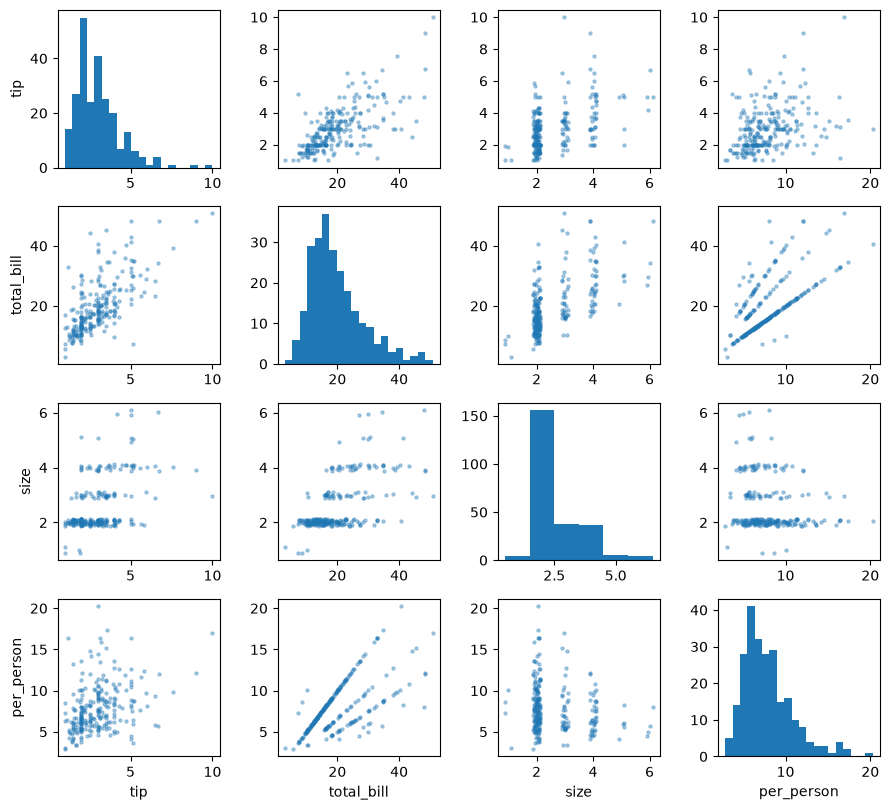

              tip  total_bill   size  per_person
tip         1.000       0.676  0.489       0.347
total_bill  0.676       1.000  0.598       0.647
size        0.489       0.598  1.000      -0.175
per_person  0.347       0.647 -0.175       1.000


In [2]:
cols = ['tip', 'total_bill', 'size', 'per_person']
fig, ax = plt.subplots(4, 4, figsize=(9, 8.2))
jit = np.random.default_rng(0).uniform(-.12, .12, n)
for i, a in enumerate(cols):
    for j, b_ in enumerate(cols):
        if i == j:
            ax[i, j].hist(df[a], bins=20 if a != 'size' else np.arange(.5, 7.5, 1))
        else:
            ax[i, j].scatter(df[b_] + (jit if b_ == 'size' else 0), df[a] + (jit if a == 'size' else 0), s=5, alpha=.35)
        if i == 3: ax[i, j].set_xlabel(b_)
        if j == 0: ax[i, j].set_ylabel(a)
plt.tight_layout()
plt.savefig('images/scatter_matrix.png')
plt.show()
print(df[cols].corr().round(3))

## Extra sums of squares

$$SSR(X_2\mid X_1)=SSE(X_1)-SSE(X_1,X_2)=SSR(X_1,X_2)-SSR(X_1),$$

the marginal reduction in error from adding $X_2$ given $X_1$. $SSR$ splits into a sequence of them, and **the order
matters** (L6, slides 6–7).

In [3]:
def SSE(*keys): return models[tuple(sorted(keys))]['SSE']
def SSR_extra(add, given):
    return SSE(*given) - SSE(*given, add)           # SSR(add | given)

SSR_full = SSTO - F3['SSE']
print(f'SSR(X1,X2,X3) = {SSR_full:.3f}\n')
for order in [('X1', 'X2', 'X3'), ('X3', 'X2', 'X1')]:
    parts, given = [], []
    for k in order:
        parts.append(SSR_extra(k, given)); given.append(k)
    lab = [f'SSR({order[0]})', f'SSR({order[1]}|{order[0]})', f'SSR({order[2]}|{order[0]},{order[1]})']
    print('order', ' -> '.join(order))
    for l, v in zip(lab, parts): print(f'   {l:<18}{v:>9.3f}')
    print(f'   {"sum":<18}{sum(parts):>9.3f}   (= SSR full: {np.isclose(sum(parts), SSR_full)})')

# cross-check: statsmodels sequential (Type I) sums of squares follow the formula order
for f_ in ['tip ~ total_bill + size + per_person', 'tip ~ per_person + size + total_bill']:
    tab = sm.stats.anova_lm(smf.ols(f_, data=df).fit(), typ=1)
    print('\nstatsmodels sequential SS for', f_.split('~')[1].strip())
    print(tab['sum_sq'].round(3).to_string())

SSR(X1,X2,X3) = 218.960

order X1 -> X2 -> X3
   SSR(X1)             212.424
   SSR(X2|X1)            5.235
   SSR(X3|X1,X2)         1.301
   sum                 218.960   (= SSR full: True)
order X3 -> X2 -> X1
   SSR(X3)              56.143
   SSR(X2|X3)          145.319
   SSR(X1|X3,X2)        17.498
   sum                 218.960   (= SSR full: True)

statsmodels sequential SS for total_bill + size + per_person
total_bill    212.424
size            5.235
per_person      1.301
Residual      246.253

statsmodels sequential SS for per_person + size + total_bill
per_person     56.143
size          145.319
total_bill     17.498
Residual      246.253


## Partial $F$ tests

Single coefficient (the general linear test, full vs. reduced): $F^*=\dfrac{SSR(X_k\mid\text{others})/1}{MSE(F)}=(t^*)^2$.

Subset: $F^*=\dfrac{[SSE(R)-SSE(F)]/(df_R-df_F)}{SSE(F)/(n-p)}$, compared with $F(1-\alpha;\,p-q,\,n-p)$.

In [4]:
MSE_F, dfF = F3['MSE'], n - F3['p']
se3 = np.sqrt(np.diag(F3['cov']))
print(f'full model: p = {F3["p"]}, df = {dfF}, MSE(F) = {MSE_F:.4f}\n')

print('single coefficient, given the other two:')
print(f'{"":<12}{"SSR(Xk|others)":>16}{"F*":>9}{"t*":>9}{"P":>11}   F(0.95;1,{dfF}) = {stats.f.ppf(.95, 1, dfF):.3f}')
for i, k in enumerate(['X1', 'X2', 'X3']):
    others = [o for o in ['X1', 'X2', 'X3'] if o != k]
    ssr = SSR_extra(k, others); Fs = ssr / MSE_F; t_ = F3['b'][i + 1] / se3[i + 1]
    assert np.isclose(Fs, t_**2)
    print(f'{name[k]:<12}{ssr:>16.4f}{Fs:>9.3f}{t_:>+9.3f}{stats.f.sf(Fs, 1, dfF):>11.3g}')
print('(F* = t*^2 for every coefficient.)\n')

print('pairs of coefficients dropped together:')
print(f'{"drop":<24}{"SSR(added|rest)":>16}{"F*":>9}{"P":>11}   F(0.95;2,{dfF}) = {stats.f.ppf(.95, 2, dfF):.3f}')
for drop in [('X2', 'X3'), ('X1', 'X3'), ('X1', 'X2')]:
    rest = [k for k in ['X1', 'X2', 'X3'] if k not in drop]
    ssr = SSE(*rest) - F3['SSE']; Fs = ssr / 2 / MSE_F
    print(f'{" + ".join(name[d] for d in drop):<24}{ssr:>16.4f}{Fs:>9.3f}{stats.f.sf(Fs, 2, dfF):>11.3g}')

ft = smf.ols('tip ~ total_bill + size + per_person', data=df).fit().f_test('size = 0, per_person = 0')
Fchk = (SSE('X1') - F3['SSE']) / 2 / MSE_F
assert np.isclose(float(ft.fvalue), Fchk), 'statsmodels f_test disagrees'
print('\nstatsmodels f_test reproduces the (size, per_person) subset test.')

full model: p = 4, df = 240, MSE(F) = 1.0261

single coefficient, given the other two:
              SSR(Xk|others)       F*       t*          P   F(0.95;1,240) = 3.880
total_bill           17.4983   17.054   +4.130   5.02e-05
size                  0.0269    0.026   -0.162      0.872
per_person            1.3012    1.268   -1.126      0.261
(F* = t*^2 for every coefficient.)

pairs of coefficients dropped together:
drop                     SSR(added|rest)       F*          P   F(0.95;2,240) = 3.033
size + per_person                 6.5361    3.185     0.0431
total_bill + per_person         107.5818   52.425   1.29e-19
total_bill + size               162.8171   79.341   3.55e-27

statsmodels f_test reproduces the (size, per_person) subset test.


## Coefficients of partial determination

$$R^2_{Y2\mid1}=\frac{SSR(X_2\mid X_1)}{SSE(X_1)},\qquad R^2_{Y3\mid12}=\frac{SSR(X_3\mid X_1,X_2)}{SSE(X_1,X_2)}:$$

the share of the variation **left over** by the other predictors that adding $X_k$ explains. The signed square root is
the partial correlation.

In [5]:
def partial_R2(add, given):
    return SSR_extra(add, given) / SSE(*given)

pairs = [('X2', ['X1']), ('X3', ['X1']), ('X3', ['X1', 'X2']), ('X2', ['X1', 'X3']), ('X1', ['X2', 'X3'])]
print(f'{"quantity":<14}{"R2 partial":>12}{"partial r":>11}')
for add, given in pairs:
    r2 = partial_R2(add, given)
    sign = np.sign(models[tuple(sorted(given + [add]))]['b'][1 + sorted(given + [add]).index(add)])
    print(f'R2_Y{add[1]}|{"".join(g[1] for g in given):<8}{r2:>12.4f}{sign*np.sqrt(r2):>+11.4f}')

# check one partial correlation as a correlation of residuals
def resid(target, keys):
    Xm = np.column_stack([np.ones(n)] + [V[k] for k in keys])
    return target - Xm @ np.linalg.lstsq(Xm, target, rcond=None)[0]
r_chk = np.corrcoef(resid(Y, ['X1', 'X2']), resid(V['X3'], ['X1', 'X2']))[0, 1]
print(f'\ncorr of residuals (Y|X1,X2) and (X3|X1,X2) = {r_chk:+.4f}  (= partial r of X3 given X1,X2)')

quantity        R2 partial  partial r
R2_Y2|1             0.0207    +0.1439
R2_Y3|1             0.0257    -0.1605
R2_Y3|12            0.0053    -0.0725
R2_Y2|13            0.0001    -0.0105
R2_Y1|23            0.0663    +0.2576

corr of residuals (Y|X1,X2) and (X3|X1,X2) = -0.0725  (= partial r of X3 given X1,X2)


## Standardized regression (correlation transformation)

$$Y_i^*=\frac1{\sqrt{n-1}}\frac{Y_i-\bar Y}{s_Y},\qquad X_{ik}^*=\frac1{\sqrt{n-1}}\frac{X_{ik}-\bar X_k}{s_k}
\quad\Rightarrow\quad \mathbf X^{*\prime}\mathbf X^*=\mathbf r_{XX},\ \ \mathbf r_{XX}\,\mathbf b^*=\mathbf r_{YX}.$$

No intercept; $b^*_k$ is the change in $Y$ in s.d. units per one-s.d. change in $X_k$, so coefficients become comparable.
Back to original units: $b_k=(s_Y/s_k)\,b_k^*$.

In [6]:
keys3 = ['X1', 'X2', 'X3']
Xr = np.column_stack([V[k] for k in keys3])
sY, sk = Y.std(ddof=1), Xr.std(axis=0, ddof=1)
Ys = (Y - Y.mean()) / sY / np.sqrt(n - 1)
Xs = (Xr - Xr.mean(axis=0)) / sk / np.sqrt(n - 1)
rXX = np.corrcoef(Xr.T)
rYX = np.array([np.corrcoef(Xr[:, j], Y)[0, 1] for j in range(3)])
assert np.allclose(Xs.T @ Xs, rXX) and np.allclose(Xs.T @ Ys, rYX), 'cross-products are not the correlations'

bstar = np.linalg.solve(rXX, rYX)
b_back = sY / sk * bstar
b0_back = Y.mean() - b_back @ Xr.mean(axis=0)
assert np.allclose(np.r_[b0_back, b_back], F3['b']), 'back-transformation disagrees with the raw fit'

print('X*\'X* = r_XX and X*\'Y* = r_YX verified; the back-transformed coefficients equal the raw least-squares ones.\n')
print(f'{"":<12}{"b_k":>10}{"s_k":>9}{"b*_k":>9}')
for j, k in enumerate(keys3):
    print(f'{name[k]:<12}{F3["b"][j+1]:>10.4f}{sk[j]:>9.3f}{bstar[j]:>+9.3f}')
print(f'(s_Y = {sY:.3f})')
print(f'\ncondition number:  X\'X (raw, with intercept) = {np.linalg.cond(F3["X"].T @ F3["X"]):,.0f}   r_XX = {np.linalg.cond(rXX):,.1f}')

X*'X* = r_XX and X*'Y* = r_YX verified; the back-transformed coefficients equal the raw least-squares ones.

                   b_k      s_k     b*_k
total_bill      0.1253    8.902   +0.806
size           -0.0356    0.951   -0.024
per_person     -0.0850    2.914   -0.179
(s_Y = 1.384)

condition number:  X'X (raw, with intercept) = 49,234   r_XX = 67.8


## Multicollinearity

Predictors strongly correlated with each other: the fit and predictions survive, but individual coefficients become
unstable and imprecise (L6, slides 18–23). First the correlations, then what happens to the coefficients as predictors enter.

In [7]:
print('correlation matrix of the predictors:')
print(pd.DataFrame(rXX, index=[name[k] for k in keys3], columns=[name[k] for k in keys3]).round(3))

tcrit = stats.t.ppf(1 - ALPHA / 2, dfF)
Fstar = (SSR_full / 3) / MSE_F
print(f'\nfull model: R2 = {F3["R2"]:.4f},  F* = {Fstar:.2f} (P = {stats.f.sf(Fstar, 3, dfF):.2e}),  t(0.975; {dfF}) = {tcrit:.3f}')
print(f'{"":<12}{"b":>9}{"s{b}":>9}{"t*":>9}{"P":>10}')
for j, k in enumerate(['(intercept)'] + keys3):
    nm = k if j == 0 else name[k]
    t_ = F3['b'][j] / se3[j]
    print(f'{nm:<12}{F3["b"][j]:>9.4f}{se3[j]:>9.4f}{t_:>+9.2f}{2*stats.t.sf(abs(t_), dfF):>10.3g}')
sig = [name[k] for j, k in enumerate(keys3) if abs(F3['b'][j+1] / se3[j+1]) > tcrit]
print(f'\nthe overall F is significant; individual |t*| > {tcrit:.2f} only for: {sig}')

correlation matrix of the predictors:
            total_bill   size  per_person
total_bill       1.000  0.598       0.647
size             0.598  1.000      -0.175
per_person       0.647 -0.175       1.000

full model: R2 = 0.4707,  F* = 71.13 (P = 6.02e-33),  t(0.975; 240) = 1.970
                    b     s{b}       t*         P
(intercept)    1.2806   0.5766    +2.22    0.0273
total_bill     0.1253   0.0303    +4.13  5.02e-05
size          -0.0356   0.2198    -0.16     0.872
per_person    -0.0850   0.0754    -1.13     0.261

the overall F is significant; individual |t*| > 1.97 only for: ['total_bill']


model                b(total_bill)    s{b1}  width vs. X1 only   b(size)    s{b2}
X1                          0.1050   0.0074               1.0x         -        -
X1+X2                       0.0927   0.0091               1.2x    0.1926   0.0853
X1+X2+X3                    0.1253   0.0303               4.1x   -0.0356   0.2198

the coefficient of size changes sign when per_person enters


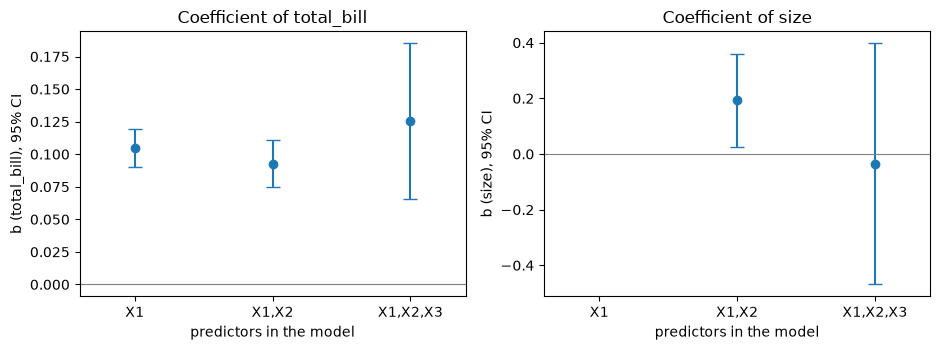

In [8]:
# how the coefficients move as predictors enter (L6, slides 21-22)
chain = [('X1',), ('X1', 'X2'), ('X1', 'X2', 'X3')]
print(f'{"model":<20}{"b(total_bill)":>14}{"s{b1}":>9}{"width vs. X1 only":>19}{"b(size)":>10}{"s{b2}":>9}')
rows = []
for k in chain:
    m = models[k]; s_ = np.sqrt(np.diag(m['cov']))
    b2 = m['b'][2] if 'X2' in k else np.nan; s2 = s_[2] if 'X2' in k else np.nan
    rows.append((k, m['b'][1], s_[1], b2, s2, m['p']))
for k, b1, s1, b2, s2, p_ in rows:
    b2s = f'{b2:>10.4f}' if not np.isnan(b2) else f'{"-":>10}'
    s2s = f'{s2:>9.4f}' if not np.isnan(s2) else f'{"-":>9}'
    print(f'{"+".join(k):<20}{b1:>14.4f}{s1:>9.4f}{s1 / rows[0][2]:>18.1f}x{b2s}{s2s}')
print('\nthe coefficient of size changes sign when per_person enters' if rows[1][3] * rows[2][3] < 0 else '')

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.6))
for a, idx, nm_ in [(ax[0], 1, 'total_bill'), (ax[1], 2, 'size')]:
    xs, bs, hs = [], [], []
    for i, (k, b1, s1, b2, s2, p_) in enumerate(rows):
        bb, ss = (b1, s1) if idx == 1 else (b2, s2)
        if np.isnan(bb): continue
        tc = stats.t.ppf(1 - ALPHA / 2, n - p_)
        xs.append(i); bs.append(bb); hs.append(tc * ss)
    a.errorbar(xs, bs, yerr=hs, fmt='o', capsize=5)
    a.axhline(0, c='gray', lw=.8)
    a.set_xticks(range(3)); a.set_xticklabels(['X1', 'X1,X2', 'X1,X2,X3'])
    a.set_xlim(-.4, 2.4); a.set_xlabel('predictors in the model'); a.set_ylabel(f'b ({nm_}), 95% CI')
    a.set_title(f'Coefficient of {nm_}')
plt.tight_layout()
plt.savefig('images/coef_stability.png')
plt.show()

### Variance inflation factor

$$VIF_k=\frac1{1-R_k^2},$$

$R_k^2$ from regressing $X_k$ on the other predictors; $VIF>10$ is the usual warning (L6, slide 24).

total_bill   R2_k = 0.9421   VIF =  17.28   > 10
size         R2_k = 0.9034   VIF =  10.35   > 10
per_person   R2_k = 0.9126   VIF =  11.45   > 10

statsmodels variance_inflation_factor reproduces all three.
two-predictor model (X1, X2): VIF = 1.56 for both


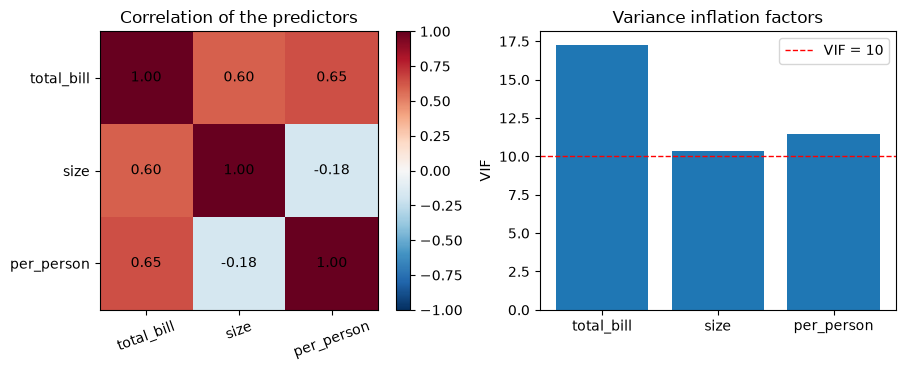

In [9]:
vif = {}
for j, k in enumerate(keys3):
    others = [o for o in keys3 if o != k]
    Xo = np.column_stack([np.ones(n)] + [V[o] for o in others])
    res = V[k] - Xo @ np.linalg.lstsq(Xo, V[k], rcond=None)[0]
    R2k = 1 - (res @ res) / ((V[k] - V[k].mean())**2).sum()
    vif[k] = 1 / (1 - R2k)
    assert np.isclose(vif[k], variance_inflation_factor(F3['X'], j + 1)), 'statsmodels disagrees'
    print(f'{name[k]:<12} R2_k = {R2k:.4f}   VIF = {vif[k]:6.2f}   {"> 10" if vif[k] > 10 else "<= 10"}')
print('\nstatsmodels variance_inflation_factor reproduces all three.')
print(f'two-predictor model (X1, X2): VIF = {1/(1-np.corrcoef(V["X1"], V["X2"])[0,1]**2):.2f} for both')

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.8))
im = ax[0].imshow(rXX, vmin=-1, vmax=1, cmap='RdBu_r')
ax[0].set_xticks(range(3)); ax[0].set_yticks(range(3))
ax[0].set_xticklabels([name[k] for k in keys3], rotation=20); ax[0].set_yticklabels([name[k] for k in keys3])
for i in range(3):
    for j in range(3): ax[0].text(j, i, f'{rXX[i, j]:.2f}', ha='center', va='center')
plt.colorbar(im, ax=ax[0], fraction=.046)
ax[0].set_title('Correlation of the predictors')
ax[1].bar([name[k] for k in keys3], [vif[k] for k in keys3])
ax[1].axhline(10, c='r', ls='--', lw=1, label='VIF = 10')
ax[1].set_ylabel('VIF'); ax[1].set_title('Variance inflation factors'); ax[1].legend()
plt.tight_layout()
plt.savefig('images/vif_corr.png')
plt.show()

### What multicollinearity does not ruin

The fit, the predictions inside the data and the unbiasedness of the estimators; it damages the individual
coefficients and their precision (L6, slide 23).

In [10]:
m2, m3 = models[('X1', 'X2')], models[('X1', 'X2', 'X3')]
print(f'R2:  (X1,X2) = {m2["R2"]:.4f}    (X1,X2,X3) = {m3["R2"]:.4f}\n')

Xh_bill, Xh_size = 20.0, 3.0
for lab, m, xh in [('(X1,X2)', m2, np.array([1, Xh_bill, Xh_size])),
                   ('(X1,X2,X3)', m3, np.array([1, Xh_bill, Xh_size, Xh_bill / Xh_size]))]:
    yh = xh @ m['b']; s_ = np.sqrt(xh @ m['cov'] @ xh)
    print(f'{lab:<12} bill 20, size 3:  Yhat_h = {yh:.4f}   s{{Yhat_h}} = {s_:.4f}')

# the same ill-conditioning shows in the coefficients but not in the mean response
rng_b = np.random.default_rng(0)
B = 2000
bb1 = np.empty(B); yy = np.empty(B)
Xf = F3['X']; xh3 = np.array([1, Xh_bill, Xh_size, Xh_bill / Xh_size])
for i in range(B):
    idx = rng_b.integers(0, n, n)
    bq = np.linalg.lstsq(Xf[idx], Y[idx], rcond=None)[0]
    bb1[i] = bq[2]; yy[i] = xh3 @ bq
print(f'\nbootstrap ({B} resamples), full model:')
print(f'  sd of the size coefficient b2 = {bb1.std(ddof=1):.4f}   (mean {bb1.mean():+.4f})')
print(f'  sd of Yhat_h at (20, 3)       = {yy.std(ddof=1):.4f}')

R2:  (X1,X2) = 0.4679    (X1,X2,X3) = 0.4707

(X1,X2)      bill 20, size 3:  Yhat_h = 3.1010   s{Yhat_h} = 0.0740
(X1,X2,X3)   bill 20, size 3:  Yhat_h = 3.1136   s{Yhat_h} = 0.0748

bootstrap (2000 resamples), full model:
  sd of the size coefficient b2 = 0.3237   (mean -0.0267)
  sd of Yhat_h at (20, 3)       = 0.0765


## Summary

- Sequential $SSR$ depends on the order: $SSR(X_2\mid X_1)=5.2$ but $SSR(X_2\mid X_3)=145.3$.
- Given the other two, only `total_bill` is needed ($t^*=4.13$); `size` and `per_person` are not
  ($P=0.87$, $0.26$), although dropping the pair together is rejected at 5% ($F^*=3.19$ vs $3.03$).
- Standardized coefficients $+0.806$, $-0.024$, $-0.179$: comparable, but the signs and sizes are another symptom of the overlap.
- VIFs $17.3$, $10.4$, $11.4$ (all above 10; $1.56$ without `per_person`): `size`'s coefficient flips sign
  ($+0.193\to-0.036$) and $s\{b_1\}$ grows $4.1\times$, while $R^2$ and the prediction at (20, 3) barely move
  ($3.10\to3.11$).


---

# Lecture 5.2 · Quantitative and Qualitative Predictors

Following `05_2_Quantitative and qualitative predictors.pdf` (Kutner et al., 2005, Ch. 8). Still the general linear
model $\mathbf Y=\mathbf X\boldsymbol\beta+\boldsymbol\varepsilon$: only the columns of $\mathbf X$ change.

Here: polynomial and interaction terms in `total_bill` ($X_1$) and `size` ($X_2$); indicator variables for `smoker`,
`sex`, `time` and `day`.

## Polynomial regression and centering

$$Y_i=\beta_0+\beta_1x_i+\beta_{11}x_i^2+\varepsilon_i,\qquad x_i=X_i-\bar X .$$

$X$ and $X^2$ are strongly correlated over a positive range; centering reduces this (L5.2, slides 6–7).

corr(X1, X1^2) = 0.9708   raw
corr(x1, x1^2) = 0.6326   centered
(skewness of total_bill = +1.126: centering gives zero correlation only for a symmetric X)
condition number of X'X:  raw 12,046,024   centered 39,751

                       b      s{b}       t*         P
intercept       3.002786  0.080995  +37.074    0.0000
x               0.105596  0.009529  +11.081    0.0000
x^2            -0.000057  0.000603   -0.095    0.9246

partial F for the squared term = 0.0090 = t*^2, P = 0.9246
R2 / R2_a:  linear 0.4566 / 0.4544    quadratic 0.4566 / 0.4521

original scale: Yhat = 0.8911 + 0.10786 X + (-5.71e-05) X^2   (equals the fit on raw X, X^2)


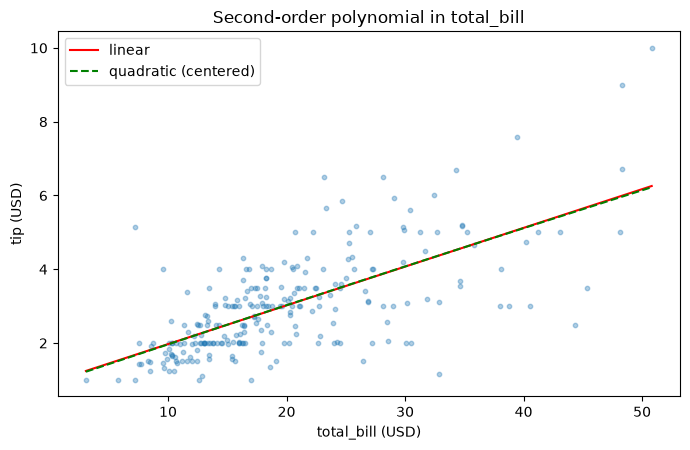

In [11]:
X1, X2 = V['X1'], V['X2']
x1, x2 = X1 - X1.mean(), X2 - X2.mean()

print(f'corr(X1, X1^2) = {np.corrcoef(X1, X1**2)[0, 1]:.4f}   raw')
print(f'corr(x1, x1^2) = {np.corrcoef(x1, x1**2)[0, 1]:.4f}   centered')
print(f'(skewness of total_bill = {stats.skew(X1):+.3f}: centering gives zero correlation only for a symmetric X)')
print(f'condition number of X\'X:  raw {np.linalg.cond(np.c_[np.ones(n), X1, X1**2].T @ np.c_[np.ones(n), X1, X1**2]):,.0f}'
      f'   centered {np.linalg.cond(np.c_[np.ones(n), x1, x1**2].T @ np.c_[np.ones(n), x1, x1**2]):,.0f}\n')

fit_lin = sm.OLS(Y, sm.add_constant(x1)).fit()
Xq = np.column_stack([np.ones(n), x1, x1**2])
fit_q = sm.OLS(Y, Xq).fit()
print(f'{"":<12}{"b":>12}{"s{b}":>10}{"t*":>9}{"P":>10}')
for nm_, bk, sk, tk, pk in zip(['intercept', 'x', 'x^2'], fit_q.params, fit_q.bse, fit_q.tvalues, fit_q.pvalues):
    print(f'{nm_:<12}{bk:>12.6f}{sk:>10.6f}{tk:>+9.3f}{pk:>10.4f}')

F_sq = (fit_lin.ssr - fit_q.ssr) / (fit_q.ssr / (n - 3))
assert np.isclose(F_sq, fit_q.tvalues[2]**2)
print(f'\npartial F for the squared term = {F_sq:.4f} = t*^2, P = {stats.f.sf(F_sq, 1, n - 3):.4f}')
print(f'R2 / R2_a:  linear {fit_lin.rsquared:.4f} / {fit_lin.rsquared_adj:.4f}    quadratic {fit_q.rsquared:.4f} / {fit_q.rsquared_adj:.4f}')

# back to the original scale: b11 = b11', b1 = b1' - 2 b11' Xbar, b0 = b0' - b1' Xbar + b11' Xbar^2  (textbook form)
xb = X1.mean(); c0, c1, c11 = fit_q.params
b11 = c11; b1o = c1 - 2 * c11 * xb; b0o = c0 - c1 * xb + c11 * xb**2
fit_raw = sm.OLS(Y, np.column_stack([np.ones(n), X1, X1**2])).fit()
assert np.allclose([b0o, b1o, b11], fit_raw.params), 'back-transformation disagrees'
print(f'\noriginal scale: Yhat = {b0o:.4f} + {b1o:.5f} X + ({b11:.2e}) X^2   (equals the fit on raw X, X^2)')

grid = np.linspace(X1.min(), X1.max(), 200)
plt.figure(figsize=(7, 4.6))
plt.scatter(X1, Y, s=10, alpha=.35)
plt.plot(grid, fit_lin.params[0] + fit_lin.params[1] * (grid - xb), 'r-', label='linear')
plt.plot(grid, fit_q.params[0] + fit_q.params[1] * (grid - xb) + fit_q.params[2] * (grid - xb)**2, 'g--', label='quadratic (centered)')
plt.xlabel('total_bill (USD)'); plt.ylabel('tip (USD)'); plt.legend()
plt.title('Second-order polynomial in total_bill')
plt.tight_layout()
plt.savefig('images/poly_fit.png')
plt.show()

### Two quantitative predictors: second-order model and interaction (8.2)

$$Y=\beta_0+\beta_1x_1+\beta_2x_2+\beta_{11}x_1^2+\beta_{22}x_2^2+\beta_{12}x_1x_2+\varepsilon .$$

With a cross-product term the slope in $X_1$ is $\beta_1+\beta_3X_2$: additive means parallel, interacting means non-parallel
(slide 10).

term                 b      s{b}       t*         P
intercept       3.0170    0.0953   +31.67    0.0000
x1              0.0943    0.0121    +7.80    0.0000
x2              0.1954    0.1246    +1.57    0.1184
x1^2           -0.0004    0.0009    -0.47    0.6378
x2^2           -0.0461    0.0766    -0.60    0.5479
x1*x2           0.0110    0.0132    +0.83    0.4077

R2_a: additive 0.4635    second-order 0.4583
partial F for the three second-order terms together: F* = 0.240 on (3, 238) df, P = 0.869

interaction model: b3 = +0.00394,  t* = +0.53,  P = 0.597
  size    slope of bill = b1 + b3*size                95% CI
     1                          0.0858   [ 0.0545,  0.1172]
     2                          0.0898   [ 0.0687,  0.1108]
     3                          0.0937   [ 0.0753,  0.1121]
     4                          0.0976   [ 0.0719,  0.1234]
     5                          0.1016   [ 0.0640,  0.1392]
     6                          0.1055   [ 0.0545,  0.1565]


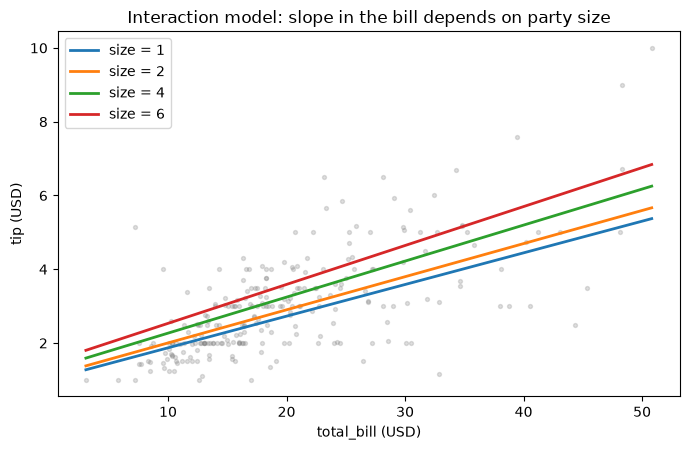

In [12]:
Xs2 = np.column_stack([np.ones(n), x1, x2, x1**2, x2**2, x1 * x2])
fit2 = sm.OLS(Y, Xs2).fit()
fit_add = sm.OLS(Y, np.column_stack([np.ones(n), x1, x2])).fit()
print(f'{"term":<12}{"b":>10}{"s{b}":>10}{"t*":>9}{"P":>10}')
for nm_, bk, sk, tk, pk in zip(['intercept', 'x1', 'x2', 'x1^2', 'x2^2', 'x1*x2'], fit2.params, fit2.bse, fit2.tvalues, fit2.pvalues):
    print(f'{nm_:<12}{bk:>10.4f}{sk:>10.4f}{tk:>+9.2f}{pk:>10.4f}')
print(f'\nR2_a: additive {fit_add.rsquared_adj:.4f}    second-order {fit2.rsquared_adj:.4f}')
F3t = ((fit_add.ssr - fit2.ssr) / 3) / (fit2.ssr / (n - 6))
print(f'partial F for the three second-order terms together: F* = {F3t:.3f} on (3, {n-6}) df, P = {stats.f.sf(F3t, 3, n - 6):.3f}')

# interaction between the two quantitative predictors, original scale: slope of total_bill at each party size
fit_int = sm.OLS(Y, np.column_stack([np.ones(n), X1, X2, X1 * X2])).fit()
b_, cv = fit_int.params, fit_int.cov_params()
print(f'\ninteraction model: b3 = {b_[3]:+.5f},  t* = {fit_int.tvalues[3]:+.2f},  P = {fit_int.pvalues[3]:.3f}')
tq = stats.t.ppf(1 - ALPHA / 2, n - 4)
print(f'{"size":>6}{"slope of bill = b1 + b3*size":>32}{"95% CI":>22}')
for s_ in range(1, 7):
    sl = b_[1] + b_[3] * s_
    se_ = np.sqrt(cv[1, 1] + s_**2 * cv[3, 3] + 2 * s_ * cv[1, 3])
    print(f'{s_:>6}{sl:>32.4f}   [{sl - tq*se_:7.4f}, {sl + tq*se_:7.4f}]')

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(X1, Y, s=8, alpha=.25, color='gray')
xs_ = np.linspace(X1.min(), X1.max(), 50)
for s_, c_ in [(1, 'C0'), (2, 'C1'), (4, 'C2'), (6, 'C3')]:
    ax.plot(xs_, b_[0] + b_[2] * s_ + (b_[1] + b_[3] * s_) * xs_, color=c_, lw=2, label=f'size = {s_}')
ax.set_xlabel('total_bill (USD)'); ax.set_ylabel('tip (USD)'); ax.legend()
ax.set_title('Interaction model: slope in the bill depends on party size')
plt.tight_layout()
plt.savefig('images/interaction_lines.png')
plt.show()

## Indicator variables

A class has no numeric scale, so encode it with 0/1 indicators. **$c$ classes need $c-1$ indicators**: $c$ indicators plus the
intercept make a column of $\mathbf X$ equal to the sum of the others, and $\mathbf X'\mathbf X$ is singular (slide 12).
The class coded all zeros is the baseline; an indicator's coefficient is that class's shift relative to it.

parallel lines:  Yhat = 0.9632 + 0.1057 X1 + -0.1489 Z
  non-smokers (Z=0): 0.9632 + 0.1057 X1
  smokers     (Z=1): 0.8143 + 0.1057 X1
b2 = -0.1489, s{b2} = 0.1352, 95% CI = [-0.415, 0.117],  P = 0.272

day has c = 4 classes (Fri: 19, Sat: 87, Sun: 76, Thur: 62)
intercept + 4 indicators: 5 columns, rank 4;  smallest eigenvalue of X'X = -2.62e-14  -> singular

baseline         SSE  b(total_bill)   indicator coefficients (shift relative to the baseline)
Fri         251.7386        0.10467   Sat -0.086, Sun +0.075, Thur -0.019
Sat         251.7386        0.10467   Fri +0.086, Sun +0.161, Thur +0.067
Sun         251.7386        0.10467   Fri -0.075, Sat -0.161, Thur -0.094
Thur        251.7386        0.10467   Fri +0.019, Sat -0.067, Sun +0.094

fitted values are identical for every choice of baseline.


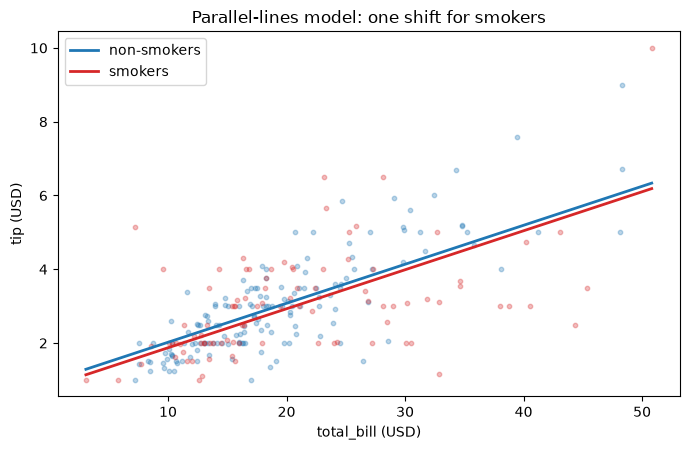

In [13]:
Z = (df['smoker'] == 'Yes').to_numpy().astype(float)          # 1 = smoker, 0 = non-smoker (baseline)
par = sm.OLS(Y, np.column_stack([np.ones(n), X1, Z])).fit()
tq2 = stats.t.ppf(1 - ALPHA / 2, n - 3)
print(f'parallel lines:  Yhat = {par.params[0]:.4f} + {par.params[1]:.4f} X1 + {par.params[2]:.4f} Z')
print(f'  non-smokers (Z=0): {par.params[0]:.4f} + {par.params[1]:.4f} X1')
print(f'  smokers     (Z=1): {par.params[0] + par.params[2]:.4f} + {par.params[1]:.4f} X1')
lo, hi = par.params[2] - tq2 * par.bse[2], par.params[2] + tq2 * par.bse[2]
print(f'b2 = {par.params[2]:+.4f}, s{{b2}} = {par.bse[2]:.4f}, 95% CI = [{lo:.3f}, {hi:.3f}],  P = {par.pvalues[2]:.3f}')

# c indicators + intercept: singular
days = ['Fri', 'Sat', 'Sun', 'Thur']
Dm = np.column_stack([(df['day'] == d_).to_numpy().astype(float) for d_ in days])
A_c = np.column_stack([np.ones(n), Dm])
print(f'\nday has c = {len(days)} classes ({", ".join(f"{d_}: {int(Dm[:, i].sum())}" for i, d_ in enumerate(days))})')
print(f'intercept + {len(days)} indicators: {A_c.shape[1]} columns, rank {np.linalg.matrix_rank(A_c)};  '
      f'smallest eigenvalue of X\'X = {np.linalg.eigvalsh(A_c.T @ A_c).min():.2e}  -> singular')

# c - 1 indicators: the baseline changes the coefficients, not the fit
print(f'\n{"baseline":<10}{"SSE":>10}{"b(total_bill)":>15}   indicator coefficients (shift relative to the baseline)')
ref_fit = None
for base in days:
    keep = [i for i, d_ in enumerate(days) if d_ != base]
    Am = np.column_stack([np.ones(n), X1, Dm[:, keep]])
    f_ = sm.OLS(Y, Am).fit()
    if ref_fit is None: ref_fit = f_
    shifts = ', '.join(f'{days[i]} {c:+.3f}' for i, c in zip(keep, f_.params[2:]))
    print(f'{base:<10}{f_.ssr:>10.4f}{f_.params[1]:>15.5f}   {shifts}')
    assert np.allclose(f_.fittedvalues, ref_fit.fittedvalues), 'fitted values changed with the baseline'
print('\nfitted values are identical for every choice of baseline.')

fig, ax = plt.subplots(figsize=(7, 4.6))
for g_, c_, lab in [(0, 'C0', 'non-smokers'), (1, 'C3', 'smokers')]:
    ax.scatter(X1[Z == g_], Y[Z == g_], s=10, alpha=.3, color=c_)
    ax.plot(grid_x := np.linspace(X1.min(), X1.max(), 50), par.params[0] + par.params[1] * grid_x + g_ * par.params[2], color=c_, lw=2, label=lab)
ax.set_xlabel('total_bill (USD)'); ax.set_ylabel('tip (USD)'); ax.legend()
ax.set_title('Parallel-lines model: one shift for smokers')
plt.tight_layout()
plt.savefig('images/parallel_lines.png')
plt.show()

## Comparing regression functions

Indicator plus interaction: $E\{Y\}=\beta_0+\beta_1X_1+\beta_2Z+\beta_3X_1Z$. Slope $\beta_1$ for the baseline, $\beta_1+\beta_3$ for the
other class. Partial $F$ / $t$ tests (slide 21):

| question | hypothesis | if not rejected |
|---|---|---|
| same slope? | $\beta_3=0$ | parallel |
| same intercept? | $\beta_2=0$ | same height at $X_1=0$ |
| identical functions? | $\beta_2=\beta_3=0$ | coincident |

$X_1=0$ lies outside the data (smallest bill 3.07), so $\beta_2=0$ is read from the parallel-lines model instead.

full model: Yhat = 0.3601 + 0.1372 X1 + (+1.2042) Z + (-0.0676) X1 Z
  non-smokers: slope 0.1372      smokers: slope 0.0696

hypothesis                         F*          df          P
b3 = 0   (parallel)            22.675    (1, 240)   3.32e-06
b2 = b3 = 0   (coincident)     11.999    (2, 240)   1.08e-05
b2 = 0 in the parallel model: P = 0.272

SSE(full) = 229.8094 = SSE of the two separate regressions 229.8094.
robust (HC3) P for b3 = 0.0081   (ordinary: 3.32e-06)


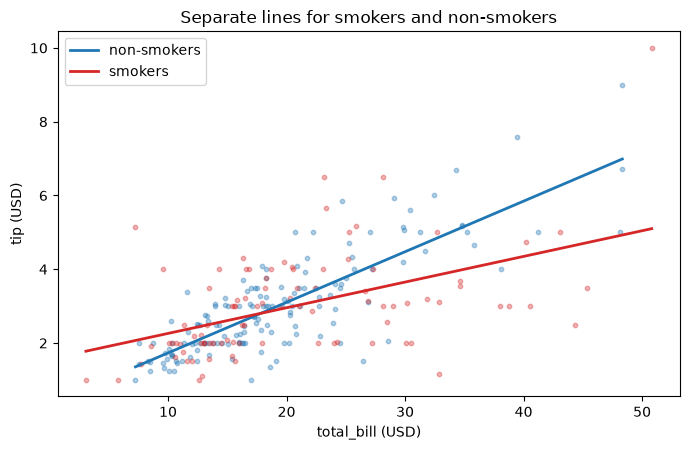

In [14]:
A_full = np.column_stack([np.ones(n), X1, Z, X1 * Z])
full = sm.OLS(Y, A_full).fit()
SSE_F, df_F = full.ssr, n - 4
SSE_par = par.ssr
SSE_coin = sm.OLS(Y, sm.add_constant(X1)).fit().ssr

print(f'full model: Yhat = {full.params[0]:.4f} + {full.params[1]:.4f} X1 + ({full.params[2]:+.4f}) Z + ({full.params[3]:+.4f}) X1 Z')
print(f'  non-smokers: slope {full.params[1]:.4f}      smokers: slope {full.params[1] + full.params[3]:.4f}\n')

F_b3 = (SSE_par - SSE_F) / (SSE_F / df_F)
F_coin = ((SSE_coin - SSE_F) / 2) / (SSE_F / df_F)
print(f'{"hypothesis":<28}{"F*":>9}{"df":>12}{"P":>11}')
print(f'{"b3 = 0   (parallel)":<28}{F_b3:>9.3f}{"(1, " + str(df_F) + ")":>12}{stats.f.sf(F_b3, 1, df_F):>11.2e}')
print(f'{"b2 = b3 = 0   (coincident)":<28}{F_coin:>9.3f}{"(2, " + str(df_F) + ")":>12}{stats.f.sf(F_coin, 2, df_F):>11.2e}')
print(f'b2 = 0 in the parallel model: P = {par.pvalues[2]:.3f}')

ftest = full.f_test(np.array([[0, 0, 1, 0], [0, 0, 0, 1]]))
assert np.isclose(float(ftest.fvalue), F_coin), 'statsmodels f_test disagrees'

# the full model is two separate straight-line fits
sse_sep = 0.0
for g_ in (0, 1):
    mg = Z == g_
    sse_sep += sm.OLS(Y[mg], sm.add_constant(X1[mg])).fit().ssr
assert np.isclose(sse_sep, SSE_F)
print(f'\nSSE(full) = {SSE_F:.4f} = SSE of the two separate regressions {sse_sep:.4f}.')
hc3 = sm.OLS(Y, A_full).fit(cov_type='HC3')
print(f'robust (HC3) P for b3 = {hc3.pvalues[3]:.4f}   (ordinary: {full.pvalues[3]:.2e})')

fig, ax = plt.subplots(figsize=(7, 4.6))
for g_, c_, lab in [(0, 'C0', 'non-smokers'), (1, 'C3', 'smokers')]:
    ax.scatter(X1[Z == g_], Y[Z == g_], s=10, alpha=.35, color=c_)
    xs_ = np.linspace(X1[Z == g_].min(), X1[Z == g_].max(), 50)
    ax.plot(xs_, full.params[0] + full.params[1] * xs_ + g_ * (full.params[2] + full.params[3] * xs_), color=c_, lw=2, label=lab)
ax.set_xlabel('total_bill (USD)'); ax.set_ylabel('tip (USD)'); ax.legend()
ax.set_title('Separate lines for smokers and non-smokers')
plt.tight_layout()
plt.savefig('images/smoker_lines.png')
plt.show()

### Other qualitative predictors

More than two classes: $c-1$ indicators, and their interactions with $X_1$ give a different slope per class. The same two tests
(equal slopes: all interactions $=0$; identical functions: all indicator and interaction terms $=0$), for each variable:

In [15]:
def compare(Zm):
    c1 = Zm.shape[1]
    Af = np.column_stack([np.ones(n), X1, Zm, Zm * X1[:, None]])
    ff = sm.OLS(Y, Af).fit()
    ssr_par = sm.OLS(Y, np.column_stack([np.ones(n), X1, Zm])).fit().ssr
    ssr_coin = sm.OLS(Y, sm.add_constant(X1)).fit().ssr
    dfF = n - Af.shape[1]
    F_s = ((ssr_par - ff.ssr) / c1) / (ff.ssr / dfF)
    F_c = ((ssr_coin - ff.ssr) / (2 * c1)) / (ff.ssr / dfF)
    return F_s, c1, stats.f.sf(F_s, c1, dfF), F_c, 2 * c1, stats.f.sf(F_c, 2 * c1, dfF), dfF

specs = {'smoker (Yes/No)': (df['smoker'] == 'Yes').to_numpy(float)[:, None],
         'sex (Male/Female)': (df['sex'] == 'Male').to_numpy(float)[:, None],
         'time (Dinner/Lunch)': (df['time'] == 'Dinner').to_numpy(float)[:, None],
         'day (Sat, Sun, Thur vs Fri)': np.column_stack([(df['day'] == d_).to_numpy(float) for d_ in ['Sat', 'Sun', 'Thur']])}
print(f'{"variable":<30}{"equal slopes: F*":>18}{"P":>10}{"identical: F*":>16}{"P":>10}')
for k_, Zm in specs.items():
    F_s, d1, p_s, F_c, d2, p_c, dfF_ = compare(Zm)
    print(f'{k_:<30}{F_s:>11.3f} ({d1},{dfF_}){p_s:>10.3g}{F_c:>10.3f} ({d2},{dfF_}){p_c:>10.3g}')

variable                        equal slopes: F*         P   identical: F*         P
smoker (Yes/No)                    22.675 (1,240)  3.32e-06    11.999 (2,240)  1.08e-05
sex (Male/Female)                   0.299 (1,240)     0.585     0.168 (2,240)     0.845
time (Dinner/Lunch)                 2.095 (1,240)     0.149     1.049 (2,240)     0.352
day (Sat, Sun, Thur vs Fri)         3.659 (3,236)    0.0131     2.001 (6,236)    0.0663


## Summary

- A quadratic term in `total_bill` adds nothing ($P=0.92$). Centering lowers $\operatorname{corr}(X,X^2)$ from $0.97$ to $0.63$, not to $0$,
  because the bill is right-skewed (skewness $1.13$); the condition number of $\mathbf X'\mathbf X$ falls from $1.2\times10^7$ to $4.0\times10^4$.
- The second-order model in bill and size ($F^*=0.24$, $P=0.87$) and the bill $\times$ size interaction ($P=0.60$) add nothing.
- `smoker` matters: the slope of the tip on the bill is $0.137$ for non-smokers and $0.070$ for smokers. Equal slopes are rejected
  ($F^*=22.7$; robust $P=0.008$) and so are identical functions ($F^*=12.0$). Sex and time of day show no difference;
  `day` has different slopes at 5% ($P=0.013$) but identical functions are not rejected ($P=0.066$).
- The baseline choice changes the indicator coefficients, not the fit.
